<a href="https://colab.research.google.com/github/f0rceFOS/python-practice-algos/blob/master/636-01/hw_7_vinogradov_a_a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Задание для работы (ДЗ 7)

1. Загрузите датасет **Breast Cancer** (`sklearn.datasets.load_breast_cancer`).
2. Обучите `RandomForestClassifier` на исходных 30 признаках и замерьте accuracy.
3. Примените `PCA(n_components=0.95)` (сохранив 95% дисперсии).
4. Обучите ту же модель на сжатых признаках. Упало ли качество? Насколько сильно?
5. Попробуйте визуализировать данные через `UMAP` и раскрасить по целевому классу (malignant/benign).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Размер данных:", X.shape)
print("Классы:", data.target_names)

# Сложность в худшем случае: время O(n*d), память O(n*d).
# n — число объектов, d — число признаков.

Размер данных: (569, 30)
Классы: ['malignant' 'benign']


In [2]:
forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
accuracy_original = accuracy_score(y_test, forest.predict(X_test))

print(f"Accuracy (30 признаков): {accuracy_original:.4f}")

# Сложность обучения (консервативная верхняя оценка):
# время O(T*d*n^2*log(n)), память O(n*d + T*n).
# T — число деревьев; n — число объектов обучения; d — число признаков.

Accuracy (30 признаков): 0.9561


In [3]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Признаков до PCA:", X_train.shape[1])
print("Признаков после PCA:", X_train_pca.shape[1])
print(f"Сохранено дисперсии: {pca.explained_variance_ratio_.sum():.2%}")

# Сложность в худшем случае для полного SVD при n >= d:
# время O(n*d^2 + d^3), память O(n*d + d^2).

Признаков до PCA: 30
Признаков после PCA: 10
Сохранено дисперсии: 95.27%


In [4]:
forest_pca = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest_pca.fit(X_train_pca, y_train)
accuracy_pca = accuracy_score(y_test, forest_pca.predict(X_test_pca))

difference = (accuracy_pca - accuracy_original) * 100

print(f"Accuracy до PCA: {accuracy_original:.4f}")
print(f"Accuracy после PCA: {accuracy_pca:.4f}")
print(f"Изменение: {difference:+.2f} процентного пункта")

if difference < 0:
    print("Качество снизилось.")
elif difference > 0:
    print("Качество повысилось.")
else:
    print("Качество не изменилось.")

# Сложность обучения в худшем случае: время O(T*k*n^2*log(n)),
# память O(n*k + T*n), где k — число признаков после PCA.

Accuracy до PCA: 0.9561
Accuracy после PCA: 0.9211
Изменение: -3.51 процентного пункта
Качество снизилось.


In [5]:
%pip -q install umap-learn

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


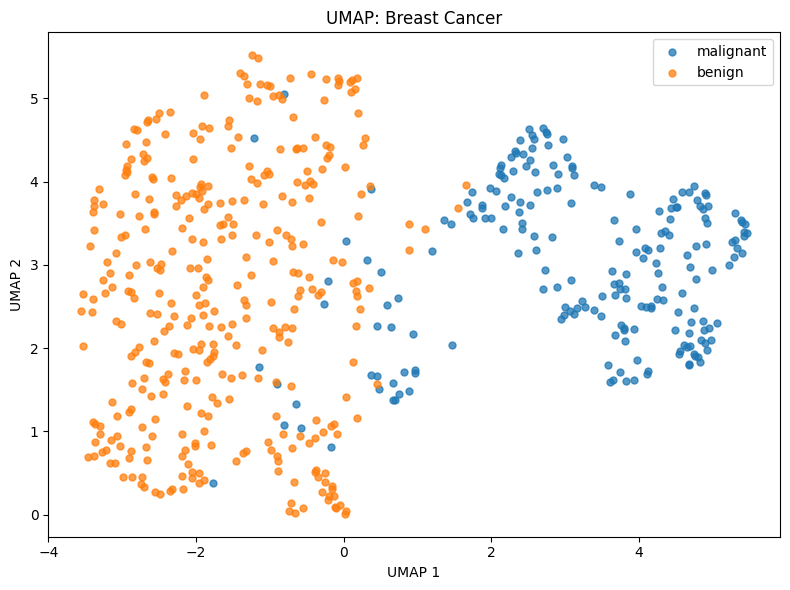

In [6]:
import umap

X_scaled = StandardScaler().fit_transform(X)
embedding = umap.UMAP(n_components=2, random_state=42).fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for label, name in enumerate(data.target_names):
    mask = y == label
    plt.scatter(
        embedding[mask, 0], embedding[mask, 1],
        s=25, alpha=0.75, label=name
    )

plt.title("UMAP: Breast Cancer")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend()
plt.tight_layout()
plt.show()

# Консервативная оценка для полного попарного поиска соседей:
# время O(n^2*d), память O(n^2 + n*d).
# Реальный UMAP использует приближённый поиск; сложность зависит от реализации.